In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F

from IPython.display import clear_output
from net.common import savefig
warnings.filterwarnings("ignore")
clear_output()

In [2]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
}
rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ob_size = 5
act_size = 3
print(f"ob_size: {ob_size}, act_size: {act_size}"   )

ob_size: 5, act_size: 3


In [3]:
from net.colei import ColEI
from net.dann import DANN
from net.simple import SimpleNet
from net.eisep import EISepNet
from net.dbp import DBPN
def train(env, net, env_vec, epoch, batch_size, seq_len, lr):

    net.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

    running_loss = 0.0
    running_entropy = 0.0
    running_decoding_loss = 0.0

    loss_log = np.zeros((epoch, 3))
    gradient_log = np.zeros((epoch, 7))

    for i in range(epoch):
        # net.set_temperature(get_temperature(i))
        # if i % 10 == 9:
            # print('Epoch:', i+1, 'Temperature:', net.temperature)
        inputs, labels = dataset()

        inputs = np.concatenate([inputs, env_vec.reshape(1,1,-1).repeat(inputs.shape[0], 0).repeat(inputs.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(inputs).type(torch.float).to(device)
        labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

        # zero the parameter gradients

        # forward + backward + optimize
        outputs, eimask_logit, hidden = net(inputs)

        decoding_loss = criterion(outputs.reshape(-1, act_size), labels)


        loss = decoding_loss

        if net.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            # running_entropy += entropy_loss.item()
            entropy_loss = net.get_ei_entropy_loss()
            loss_log[i, 2] = entropy_loss.item()
        else:
            entropy_loss = 0.0

        loss += entropy_loss * 1

        loss.backward()
        if isinstance(net, DANN):
            gradient_log[i, 0] = net.danncell.Wex.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=None)
            net.zero_grad()
        elif isinstance(net, ColEI):
            gradient_log[i, 0] = net.colcell.W_pos.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=10)
            net.zero_grad()
        elif isinstance(net, DBPN):
            gradient_log[i, 0] = net.rnn.weight_hh_l0.grad.norm(2).item()
            net.update(optimizer)
            optimizer.zero_grad()
        else:
            gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()
            if net.entropy_loss:
                gradient_log[i, 6] = net.lstm.eimask_logit.grad.norm(2).item()
            optimizer.step()
            optimizer.zero_grad()
        # gradient_log[i, 0] = net.lstm.input_layer.weight.grad.norm(2).item()
        # gradient_log[i, 1] = net.lstm.input_layer.bias.grad.norm(2).item()
        # gradient_log[i, 2] = net.lstm.Wrec_free.grad.norm(2).item()
        # gradient_log[i, 3] = net.lstm.bias.grad.norm(2).item()
        # gradient_log[i, 4] = net.lstm.output_layer.weight.grad.norm(2).item()
        # gradient_log[i, 5] = net.lstm.output_layer.bias.grad.norm(2).item()
        # if net.entropy_loss:
        #     print(net.lstm.eimask_logit.requires_grad)

        # optimizer.step()

        loss_log[i, 0] = loss.item()
        loss_log[i, 1] = decoding_loss.item()

        # print statistics
        running_loss += loss.item()
        running_decoding_loss += decoding_loss.item()
        if (i+1) % 100 == 0:
            print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
            print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
                running_entropy / 100, running_decoding_loss / 100))
            running_loss = 0.0
            running_entropy = 0.0
            running_decoding_loss = 0.0

    print('Finished Training')
    return net, loss_log, gradient_log

def test(env, net, env_vec):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial

    return perf

def continual_learning(envs, net, epoch, batch_size, seq_len, lr, repeat_times):
    """
    Continual learning on a sequence of environments.
    """
    test_perfs = np.zeros((repeat_times, len(envs), len(envs)))
    env_vecs = np.eye(len(envs))
    loss_logs = np.zeros((repeat_times, len(envs), epoch, 3))
    gradient_logs = np.zeros((repeat_times, len(envs), epoch, 7))
    net_state_dicts = [[None] * len(envs) for _ in range(repeat_times)]
    for k in range(repeat_times):
        for i, env in enumerate(envs):
            # print(f'Training on environment {i}...')
            net, loss_log, gradient_log = train(env, net, env_vecs[i], epoch, batch_size, seq_len, lr)
            loss_logs[k, i] = loss_log
            gradient_logs[k, i] = gradient_log
            net_state_dicts[k][i] = net.state_dict()
            # plot_log(loss_log, f'./output/continual_learning_supervised/loss_log_env{i}.png', ['Total loss', 'Decoding loss', 'Entropy loss'])
            # plot_log(gradient_log, f'./output/continual_learning_supervised/gradient_log_env{i}.png', ['Gradient norm'])
            for j, env_test in enumerate(envs):
                perf = test(env_test, net, env_vecs[j])
                test_perfs[k, i, j] = perf
                # print(f'Test performance on env {j} after training on env {i}: {perf:.3f}')
    return test_perfs, net_state_dicts, loss_logs, gradient_logs

def plot_sequential_performance(test_perf_EI, test_perf_simple, seed, env_names):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for i in range(len(env_names)):
        ax[0].plot(test_perf_EI[:,i], label=f'{env_names[i]} acc')
        ax[1].plot(test_perf_simple[:,i], label=f'{env_names[i]} acc')
    ax[0].set_title('EI-RNN')
    ax[1].set_title('Simple RNN')
    for i in range(2):
        ax[i].set_xticks(range(len(env_names)))
        ax[i].set_xticklabels(env_names)
        # ax[i].set_xmargin(0)
        ax[i].set_xlabel('Training environment')
        ax[i].set_ylabel('Test performance')
        ax[i].legend()
    plt.tight_layout()
    plt.savefig(f'./output/sequential_performance_seed{seed}.png')

def plot_log(log, dir, items):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3))
    for i in range(log.shape[1]):
        ax.plot(log[:, i], label=items[i])
    ax.set_xlabel('Epoch')
    ax.legend()
    plt.tight_layout()
    plt.savefig(dir)
    return


In [4]:
task_ids = ["go", "dlygo", "anti", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]

In [5]:
from net.common import init_model
import pickle as pkl
def multiple_train(model_name, lr):
    n_seed = 5
    hidden_size = 64
    epoch = 200
    repeat_times = 10
    batch_size = 32
    seq_len = 100
    # lr = 1e-3
    test_perf_all = np.zeros((n_seed, repeat_times, len(envs), len(envs)))
    net_state_dicts = [None] * n_seed
    loss_log_all = np.zeros((n_seed, repeat_times, len(envs), epoch, 3))
    gradient_log_all = np.zeros((n_seed, repeat_times, len(envs), epoch, 7))
    for i in range(n_seed):
        print('Seed:', i)
        np.random.seed(i)
        torch.manual_seed(i)
        net = init_model(ob_size=ob_size+len(envs), hidden_size=hidden_size, act_size=act_size, model_name=model_name).to(device)
        test_perf, net_state_dict, loss_log, gradient_log = continual_learning(envs, net, epoch, batch_size, seq_len, lr, repeat_times)
        test_perf_all[i] = test_perf
        net_state_dicts[i] = net_state_dict
        loss_log_all[i] = loss_log
        gradient_log_all[i] = gradient_log
    info = {
        "test_perf_all": test_perf_all,
        "net_state_dicts": net_state_dicts,
        "loss_log_all": loss_log_all,
        "gradient_log_all": gradient_log_all,
    }
    return info

In [33]:
import os
model_names = ['absolute_eisep', ]
# model_names = ['dbpn', 'colei_sgd', 'colei_adam', 'dann_sgd', 'dann_adam', 'absolute_eisep']

lrs = [1e-2]
# lrs = [5e-3]
# model_names = ['eisep']
for i, model_name in enumerate(model_names):
    print(model_name)
    info = multiple_train(model_name, lrs[i])
    path = f'./result/continual_learning/lr{lrs[i]}_{model_name}_info.pkl'
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'wb') as f:
        pkl.dump(info, f)
raise ValueError('stop here')

absolute_eisep
Seed: 0
Using UnFixed EISep RNN
100 loss: 1.09242
Entropy loss: 0.00000, Decoding loss: 1.09242
200 loss: 0.73728
Entropy loss: 0.00000, Decoding loss: 0.73728
Finished Training
100 loss: 0.40700
Entropy loss: 0.00000, Decoding loss: 0.40700
200 loss: 0.25428
Entropy loss: 0.00000, Decoding loss: 0.25428
Finished Training
100 loss: 0.12450
Entropy loss: 0.00000, Decoding loss: 0.12450
200 loss: 0.02580
Entropy loss: 0.00000, Decoding loss: 0.02580
Finished Training
100 loss: 0.15045
Entropy loss: 0.00000, Decoding loss: 0.15045
200 loss: 0.00272
Entropy loss: 0.00000, Decoding loss: 0.00272
Finished Training
100 loss: 0.27133
Entropy loss: 0.00000, Decoding loss: 0.27133
200 loss: 0.02288
Entropy loss: 0.00000, Decoding loss: 0.02288
Finished Training
100 loss: 0.01067
Entropy loss: 0.00000, Decoding loss: 0.01067
200 loss: 0.00016
Entropy loss: 0.00000, Decoding loss: 0.00016
Finished Training
100 loss: 0.27504
Entropy loss: 0.00000, Decoding loss: 0.27504
200 loss: 0.0

ValueError: stop here

In [6]:
import pickle as pkl
import numpy as np
import os
# path = f'./output/continual_learning/multiple_eisep_info.pkl'
# with open(path, 'rb') as f:
#     eisep_info = pkl.load(f)
# path = f'./output/continual_learning/multiple_simple_info.pkl'
# with open(path, 'rb') as f:
#     simple_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_entryei_info.pkl'
# with open(path, 'rb') as f:
#     entryei_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_fixed_eisep_info.pkl'
# with open(path, 'rb') as f:
#     fixed_eisep_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_ccstr_simple_info.pkl'
# with open(path, 'rb') as f:
#     fixed_entryei_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_colei_sgd_info.pkl'
# with open(path, 'rb') as f:
#     colei_sgd_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_colei_adam_info.pkl'
# with open(path, 'rb') as f:
#     colei_adam_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_dbpn_info.pkl'
# with open(path, 'rb') as f:
#     dbpn_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_dann_sgd_info.pkl'
# with open(path, 'rb') as f:
#     dann_sgd_info = pkl.load(f)
# path = f'./output/continual_learning/lr1e-2_dann_adam_info.pkl'
# with open(path, 'rb') as f:
#     dann_adam_info = pkl.load(f)
# infos = [eisep_info, simple_info, entryei_info, fixed_eisep_info, fixed_entryei_info,
#          colei_sgd_info, colei_adam_info, dbpn_info, dann_sgd_info, dann_adam_info]

# print('EISep:')
# for k,v in eisep_info.items():
#     print(k, np.array(v).shape)
# print('Simple:')
# for k,v in simple_info.items():
#     print(k, np.array(v).shape)
# test_perf_EI_all = eisep_info['test_perf_all']
# test_perf_simple_all = simple_info['test_perf_all']
# test_perf_entryei_all = entryei_info['test_perf_all']
# test_perf_fixed_eisep_all = fixed_eisep_info['test_perf_all']
# test_perf_fixed_entryei_all = fixed_entryei_info['test_perf_all']
# test_perfs = np.stack([x['test_perf_all'] for x in infos], 0)
paths = ['./result/continual_learning/lr0.01_eisep_info.pkl', './result/continual_learning/lr0.005_simple_info.pkl',
        './result/continual_learning/lr0.01_simple_info.pkl']
infos = [pkl.load(open(path, 'rb')) for path in paths]
test_perfs = [info['test_perf_all'] for info in infos]
print('EISep:')
for k,v in infos[0].items():
    print(k, np.array(v).shape)
print('Simple:')
for k,v in infos[1].items():
    print(k, np.array(v).shape)

EISep:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
gradient_log_all (5, 10, 4, 200, 7)
Simple:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
gradient_log_all (5, 10, 4, 200, 7)


./output/continual_learning/continual_learning_performance.png


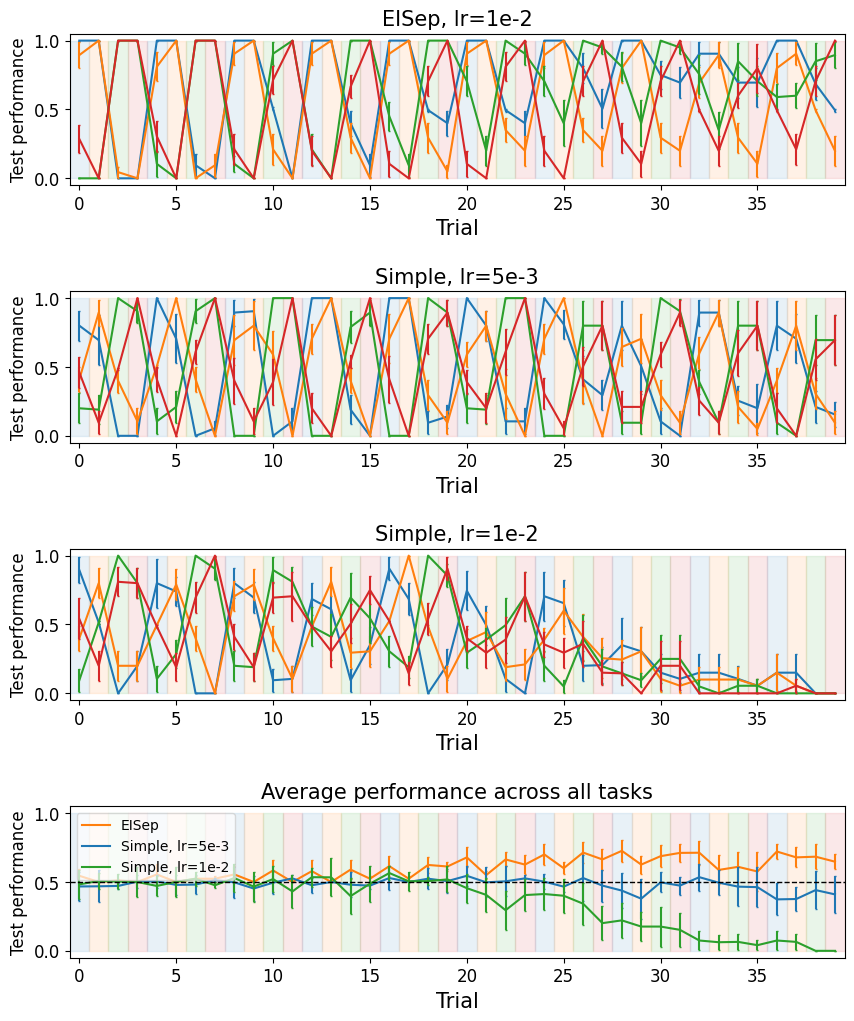

In [7]:
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
batch_size = 32
seq_len = 100
fontsize = 15
fig, ax = plt.subplots(len(infos)+1, 1, figsize=(10, 3*(len(infos)+1)))
ax = ax.flatten()
task_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
titles = ['EISep, lr=1e-2', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
summary_labels = ['EISep', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
model_colors = ['C1', 'C0', 'C2']
for i in range(len(infos)):
    test_perf = test_perfs[i]
    assert test_perf.shape == (n_seed, repeat_times, len(envs), len(envs))
    test_perf_mean = test_perf.mean(0)
    test_perf_ste = test_perf.std(0)/np.sqrt(n_seed)
    for j in range(len(envs)):
        env_perf_mean = test_perf_mean[...,j].reshape(-1)
        env_perf_ste = test_perf_ste[...,j].reshape(-1)
        ax[i].plot(env_perf_mean, color=task_colors[j], label=f'{task_ids[i]} acc')
        ax[i].errorbar(
            range(len(envs)*repeat_times),
            env_perf_mean,
            yerr=env_perf_ste,
            fmt='none',
            capsize=1,
            color=task_colors[j]
            )
    # ax[i].legend()
    ax[i].set_title(titles[i], fontsize=fontsize)
    ax[-1].plot(test_perf_mean.mean(-1).reshape(-1), label=summary_labels[i], color=model_colors[i])
    ax[-1].errorbar(
        range(len(envs)*repeat_times),
        test_perf_mean.mean(-1).reshape(-1),
        yerr=test_perf_ste.mean(-1).reshape(-1),
        fmt='none',
        capsize=1,
        color=model_colors[i]
    )

for a in ax:
    for j in range(repeat_times):
        for k in range(len(envs)):
            a.fill_betweenx([0, 1], j*len(envs)+k-0.5, j*len(envs)+k+0.5, color=task_colors[k], alpha=0.1)
    a.set_xmargin(0)
    a.set_xlabel('Trial', fontsize=fontsize)
    a.set_ylabel('Test performance', fontsize=fontsize-3)
    a.tick_params(labelsize=fontsize-3)


ax[-1].set_title('Average performance across all tasks', fontsize=fontsize)
ax[-1].legend(fontsize=fontsize-5, loc='upper left', framealpha=0.7)

ax[-1].axhline(0.5, color='k', linestyle='--', linewidth=1)

plt.subplots_adjust(hspace=0.7)
# plt.tight_layout()
figpath = './output/continual_learning/continual_learning_performance.png'
os.makedirs(os.path.dirname(figpath), exist_ok=True)
plt.savefig(figpath, dpi=400)
print(figpath)

In [ ]:
# n_seed = 5
# hidden_size = 64
# epoch = 200
# repeat_times = 10
# batch_size = 32
# seq_len = 100
# # lr = 1e-3
# fontsize = 12
# assert test_perfs.shape == (10, n_seed, repeat_times, len(envs), len(envs))
# test_perfs_mean = np.mean(test_perfs, axis=1)
# test_perfs_std = np.std(test_perfs, axis=1)/np.sqrt(n_seed)
# task_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
#           'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
# fig, ax = plt.subplots(11, 1, figsize=(10, 24))
# config_names = ['EISep', 'Simple', 'EntryEI', 'Fixed-EISep', 'Fixed-EntryEI',
#                 'ColEI-SGD', 'ColEI-Adam', 'DBPN', 'DANN-SGD', 'DANN-Adam']
# for i in range(test_perfs_mean.shape[0]):
#     for j in range(test_perfs_mean.shape[-1]):
#         perf_mean_flatten = test_perfs_mean[i][...,j].reshape(-1)
#         perf_std_flatten = test_perfs_std[i][...,j].reshape(-1)
#         ax[i].plot(perf_mean_flatten, color=task_colors[j], label=f'{task_ids[j]} acc',)
#         ax[i].errorbar(
#             range(len(envs)*repeat_times),
#             perf_mean_flatten,
#             yerr=perf_std_flatten,
#             fmt='none',
#             capsize=1,
#             color=task_colors[j]
#         )

#     ax[i].set_title(f'{config_names[i]}', fontsize=fontsize+3)

# for i in range(test_perfs_mean.shape[0]+1):
#     for j in range(repeat_times):
#         for k in range(len(envs)):
#             ax[i].fill_betweenx([0, 1], j*len(envs)+k-0.5, j*len(envs)+k+0.5, color=task_colors[k], alpha=0.1)
#     ax[i].set_xmargin(0)
#     ax[i].set_xlabel('Trial', fontsize=fontsize)
#     ax[i].set_ylabel('Test performance', fontsize=fontsize)
#     ax[i].tick_params(labelsize=fontsize-3)

# curve_colors = plt.get_cmap("Set3").colors
# for i in range(test_perfs_mean.shape[0]):
#     ax[-1].plot(test_perfs_mean[i].mean(-1).reshape(-1), label=f'{config_names[i]}', color=curve_colors[i])
#     ax[-1].errorbar(
#         range(len(envs)*repeat_times),
#         test_perfs_mean[i].mean(-1).reshape(-1),
#         yerr=test_perfs_std[i].mean(-1).reshape(-1),
#         fmt='none',
#         capsize=1,
#         color=curve_colors[i]
#     )
# ax[-1].set_title('Average performance across all tasks', fontsize=fontsize+3)
# ax[-1].legend(fontsize=fontsize-3, loc='upper left', framealpha=0.7)
# plt.subplots_adjust(hspace=0.7)
# # plt.tight_layout()
# # plt.savefig(f'./output/sequential_performance_all_configs.png', dpi=400)

AttributeError: 'list' object has no attribute 'shape'

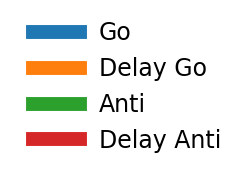

In [9]:
fig, ax = plt.subplots(1,1, figsize=(3,2))
task_names = ["Go", "Delay Go", "Anti", "Delay Anti"]
for i in range(len(envs)):
        ax.plot(np.zeros((1,)), label=task_names[i], color=task_colors[i], alpha=1, linewidth=10)
ax.legend(fontsize=fontsize+5, loc='center right', framealpha=1, shadow=False, markerscale=1, frameon=False)
ax.axis('off')
plt.savefig('./output/continual_learning/continual_learning_legend.png', dpi=500)
plt.show()

./output/continual_learning/continual_learning_loss.png


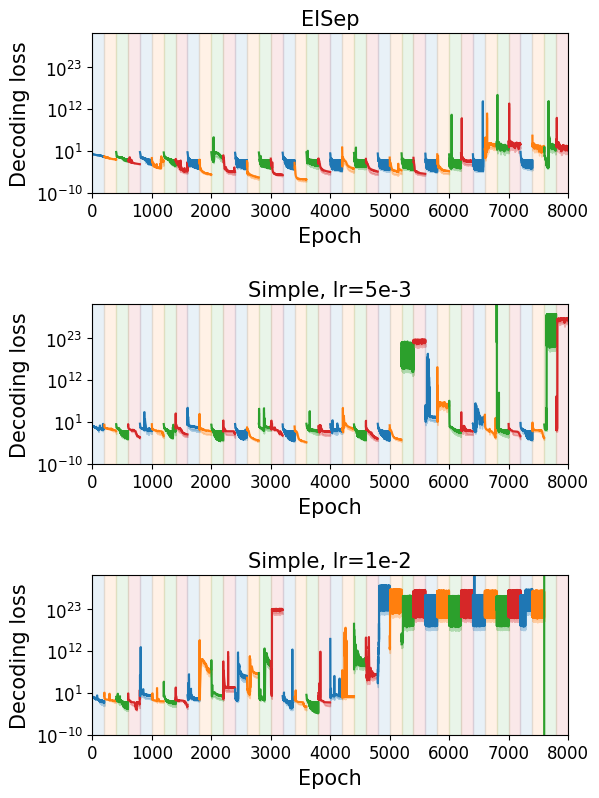

In [11]:
# from docs.examples.net import eisep

eisep_info = infos[0]
simple_info = infos[1]
n_seed = test_perfs[0].shape[0]
n_repeat_times = test_perfs[0].shape[1]
loss_idx = 1
# n_seed = test_perf_EI_all.shape[0]

# loss: [n_seed, n_repeat_times, n_train_envs, n_epoch, 3]
loss_log_ei = eisep_info['loss_log_all'][...,loss_idx]
loss_log_simple = simple_info['loss_log_all'][...,loss_idx]
# print(loss_log_ei.shape, loss_log_simple.shape)
gradient_log_ei = eisep_info['gradient_log_all'][...,0]
gradient_log_simple = simple_info['gradient_log_all'][...,0]
n_repeat_times = loss_log_ei.shape[1]
n_env = loss_log_ei.shape[2]
n_epoch = loss_log_ei.shape[3]
# loss_log_ei = loss_log_ei_origin.reshape(n_seed, -1)
# loss_log_simple = loss_log_simple_origin.reshape(n_seed, -1)

def plot_multiphase_log(log, n_env, n_epoch, n_repeat_times, ax, ylabel, title):
    assert log.shape == (n_seed, n_repeat_times, n_env, n_epoch)
    # log = log.reshape(n_seed*n_repeat_times, n_env, n_epoch)
    fontsize = 15
    log = np.where(np.isnan(log),0,log)
    mean_log = np.mean(log, axis=0)
    std_log = np.std(log, axis=0)/np.sqrt(log.shape[0])
    for i in range(n_repeat_times):
        for j in range(n_env):
            idx = i*n_env+j
            ax.plot(np.arange(idx*n_epoch, (idx+1)*n_epoch), mean_log[i,j], label=f'Env {i+1}', color=task_colors[j])
            ax.fill_between(np.arange(idx*n_epoch, (idx+1)*n_epoch), mean_log[i,j]-std_log[i,j], mean_log[i,j]+std_log[i,j], color=task_colors[j], alpha=0.3)
            ax.fill_betweenx([1e-10, 1e32], idx*n_epoch, (idx+1)*n_epoch, color=task_colors[j], alpha=0.1)
    # for j in range(n_env):
        # ax.plot(np.arange(j*n_epoch, (j+1)*n_epoch), mean_log[j], label=f'Env {i+1}', color=task_colors[j])
        # ax.fill_between(np.arange(j*n_epoch, (j+1)*n_epoch), mean_log[j]-std_log[j], mean_log[j]+std_log[j], color=task_colors[j], alpha=0.3)
        # ax.fill_betweenx([mean_log.min()/1e3, mean_log.max()], j*n_epoch, (j+1)*n_epoch, color=task_colors[j], alpha=0.1)
    ax.set_xlabel('Epoch', fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlim(0,n_repeat_times*n_env*n_epoch)
    ax.tick_params(labelsize=fontsize-3)
    # ax.set_xlim(0,n_env*n_epoch)
    # ax.legend()
    ax.set_yscale('log')
    ax.set_ylim([1e-10, 1e32])
    return

# fig, ax = plt.subplots(8, 2, figsize=(10, 18))
fig, ax = plt.subplots(3,1, figsize=(6, 8))
ax = ax.flatten()
# print(loss_log_simple)
titles = ['EISep', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
for i, info in enumerate(infos):
    loss_log = info['loss_log_all'][...,loss_idx]
    plot_multiphase_log(loss_log, n_env, n_epoch, n_repeat_times, ax[i], 'Decoding loss', titles[i])
# plot_multiphase_log(loss_log_ei, n_env, n_epoch, n_repeat_times, ax[0], 'Decoding loss', 'EISep')
# plot_multiphase_log(loss_log_simple, n_env, n_epoch, n_repeat_times, ax[1], 'Decoding loss', 'Simple')
# titles = ['Input weight', 'Input bias', 'Recurrent weight', 'Recurrent bias', 'Output weight', 'Output bias', 'E/I mask']
# for i in range(7):
#     plot_multiphase_log(eisep_info['gradient_log_all'][...,i], n_env, n_epoch, n_repeat_times, ax[2+i*2], 'Gradient norm', titles[i])
#     plot_multiphase_log(simple_info['gradient_log_all'][...,i], n_env, n_epoch, n_repeat_times, ax[3+i*2], 'Gradient norm', titles[i])

plt.tight_layout()
plt.subplots_adjust(hspace=0.7)
# plt.show()

figpath = './output/continual_learning/continual_learning_loss.png'
savefig(figpath)

In [ ]:
eisep_state_dicts = eisep_info['net_state_dicts']
simple_state_dicts = simple_info['net_state_dicts']

In [ ]:
net.lstm.Wrec_free.grad.norm(2)

tensor(3.2839e-07, device='cuda:0')

Percentage of excitatory neurons: 0.44
[ 0  1  3  6 11 16 17 19 20 21 24 25 27 28 34 35 39 40 43 44 45 47 48 51
 55 58 59 60]


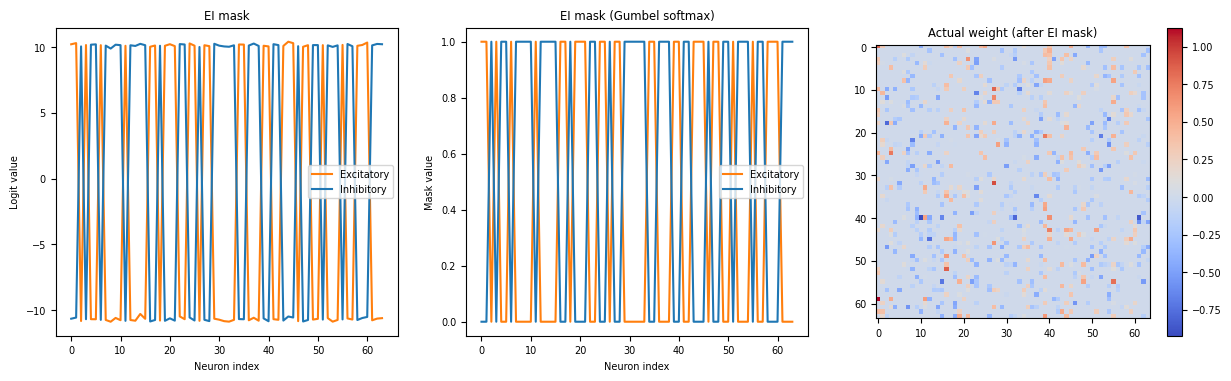

In [ ]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
# Apply the mask to the weight
weight = net.lstm.Wrec_free
corrected_weight = net.lstm.rec_filter(weight).detach().cpu().numpy()  # Apply the rectifier
actual_weight = corrected_weight @ np.diag(ei_code)  # Apply the mask to the weight
fig, ax = plt.subplots(1,3,figsize=(15, 4))
ax[0].plot(eimask[:, 0], label='Excitatory', color='C1')
ax[0].plot(eimask[:, 1], label='Inhibitory', color='C0')
ax[0].set_title('EI mask')
ax[0].set_xlabel('Neuron index')
ax[0].set_ylabel('Logit value')
ax[0].legend()
ax[1].plot(mask[:, 0], label='Excitatory', color='C1')
ax[1].plot(mask[:, 1], label='Inhibitory', color='C0')
ax[1].set_title('EI mask (Gumbel softmax)')
ax[1].set_xlabel('Neuron index')
ax[1].set_ylabel('Mask value')
ax[1].legend()
# normalized_weight = (actual_weight - np.min(actual_weight))/(np.max(actual_weight) - np.min(actual_weight)) * 2 - 1  # Normalize to [-1, 1]
im = ax[2].imshow(actual_weight, cmap='coolwarm')
ax[2].set_title('Actual weight (after EI mask)')
plt.colorbar(im, ax=ax[2])
excitatory_neurons = np.where(mask[:, 0] > mask[:, 1],1,0).mean()
print(f'Percentage of excitatory neurons: {excitatory_neurons:.2f}')
print(np.where(mask[:, 0] > mask[:, 1])[0])

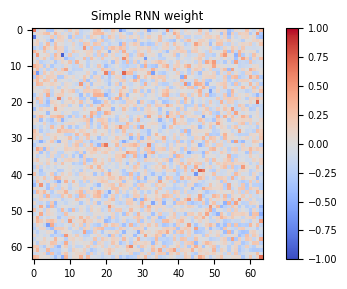

In [ ]:
simple_weight = simple_net.lstm.Wrec_free.detach().cpu().numpy()
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
im = ax.imshow(simple_weight, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('Simple RNN weight')
plt.colorbar(im, ax=ax)

In [ ]:
print((np.abs(simple_weight)>0.1).mean())
print((np.abs(actual_weight)>0.1).mean())

0.599609375
0.149658203125


In [ ]:
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size, entropy_loss=True).to(device)
# net = train(env1, net)
# print(test(env1, net))

In [ ]:
# net = train(env2, net)
# print(test(env2, net))
# print(test(env1, net))

In [ ]:
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# net = train(env1, net)
# print(test(env1, net))

In [ ]:
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size, entropy_loss=True).to(device)
# test_perf_EI = continual_learning([env1, env2], net)
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# test_perf_simple = continual_learning([env1, env2], net)

In [ ]:
# def train(env, net):
#     seq_len = 100
#     batch_size = 32

#     criterion = nn.CrossEntropyLoss()
#     optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)
#     dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

#     running_loss = 0.0
#     running_entropy = 0.0
#     running_decoding_loss = 0.0
#     for i in range(EPOCHS):
#         # net.set_temperature(get_temperature(i))
#         # if i % 10 == 9:
#             # print('Epoch:', i+1, 'Temperature:', net.temperature)
#         inputs, labels = dataset()
#         inputs = torch.from_numpy(inputs).type(torch.float).to(device)
#         labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

#         # zero the parameter gradients
#         optimizer.zero_grad()

#         # forward + backward + optimize
#         outputs, eimask_logit, hidden = net(inputs)

#         # eimask_prob = F.softmax(eimask_logit, dim=-1)
#         # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)

#         decoding_loss = criterion(outputs.view(-1, act_size), labels)
#         # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization

#         # loss = decoding_loss
#         loss = decoding_loss

#         loss.backward()
#         optimizer.step()

#         # print statistics
#         running_loss += loss.item()
#         # running_entropy += entropy_loss.item()
#         running_decoding_loss += decoding_loss.item()
#         if (i+1) % 100 == 0:
#             print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
#             print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
#                 running_entropy / 100, running_decoding_loss / 100))
#             running_loss = 0.0

#     print('Finished Training')
#     return net

In [ ]:
# EI_env2_performance = [0.995, 1.0]
# simple_env2_performance = [1.0, 0.545]
# fig, ax = plt.subplots(figsize=(4,3))
# ax.plot(EI_env2_performance, label='EI', marker='o')
# ax.plot(simple_env2_performance, label='Simple', marker='o')
# ax.set_xticks([0, 1])
# ax.set_xticklabels(['Delay-Go', 'MultiDM'])
# ax.set_ylabel('Test performance on Delay-Go')
# ax.set_xlabel('Training task')
# plt.legend()
# plt.tight_layout()
# plt.show()
